In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
df=pd.read_csv('/content/python machine learning model xgboost - electricity demand dataset.csv')

In [ ]:
df.head()

,Timestamp,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
0,01-Jan-20,0.0,2.0,1.0,2020.0,1.0,3.000000,61.288951,2457.119872
1,01-Jan-20,1.0,2.0,1.0,2020.0,1.0,3.000000,52.873702,2269.904712
2,01-Jan-20,2.0,2.0,1.0,2020.0,1.0,4.244482,36.341783,2215.640403
3,01-Jan-20,3.0,2.0,1.0,2020.0,1.0,3.000000,72.629378,2174.232413
4,01-Jan-20,4.0,2.0,1.0,2020.0,1.0,3.881208,90.582444,2472.453006


#Data preprocessing

In [ ]:
df.shape

(43848, 9)

In [ ]:
df.isnull().values.any()

np.True_

In [ ]:
df.isnull().sum()

,0
Timestamp,0
hour,11
dayofweek,9
month,8
year,5
dayofyear,5
Temperature,7
Humidity,10
Demand,7


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43848 entries, 0 to 43847
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Timestamp    43848 non-null  object 
 1   hour         43837 non-null  float64
 2   dayofweek    43839 non-null  float64
 3   month        43840 non-null  float64
 4   year         43843 non-null  float64
 5   dayofyear    43843 non-null  float64
 6   Temperature  43841 non-null  float64
 7   Humidity     43838 non-null  float64
 8   Demand       43841 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.0+ MB


#Filling Null VAlues

In [ ]:
from sklearn.impute import SimpleImputer
imputer= SimpleImputer(missing_values=np.nan, strategy="mean")
fill_col=["Demand","Humidity","Temperature", "dayofyear", "year", "month", "dayofweek", "hour"]

In [ ]:
df[fill_col]= pd.DataFrame(imputer.fit_transform(df[fill_col]), columns=fill_col,  index=df.index)

In [ ]:
df.head()

,Timestamp,hour,dayofweek,month,year,dayofyear,Temperature,Humidity,Demand
0,01-Jan-20,0.0,2.0,1.0,2020.0,1.0,3.000000,61.288951,2457.119872
1,01-Jan-20,1.0,2.0,1.0,2020.0,1.0,3.000000,52.873702,2269.904712
2,01-Jan-20,2.0,2.0,1.0,2020.0,1.0,4.244482,36.341783,2215.640403
3,01-Jan-20,3.0,2.0,1.0,2020.0,1.0,3.000000,72.629378,2174.232413
4,01-Jan-20,4.0,2.0,1.0,2020.0,1.0,3.881208,90.582444,2472.453006


In [ ]:
df.isnull().sum()

,0
Timestamp,0
hour,0
dayofweek,0
month,0
year,0
dayofyear,0
Temperature,0
Humidity,0
Demand,0


In [ ]:
x= df.drop(["Demand", "Timestamp"], axis=1)
y= df["Demand"]

In [ ]:
y.head()

,Demand
0,2457.119872
1,2269.904712
2,2215.640403
3,2174.232413
4,2472.453006


In [ ]:
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size=0.2, random_state=42)

In [ ]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(35078, 7)
(8770, 7)
(35078,)
(8770,)


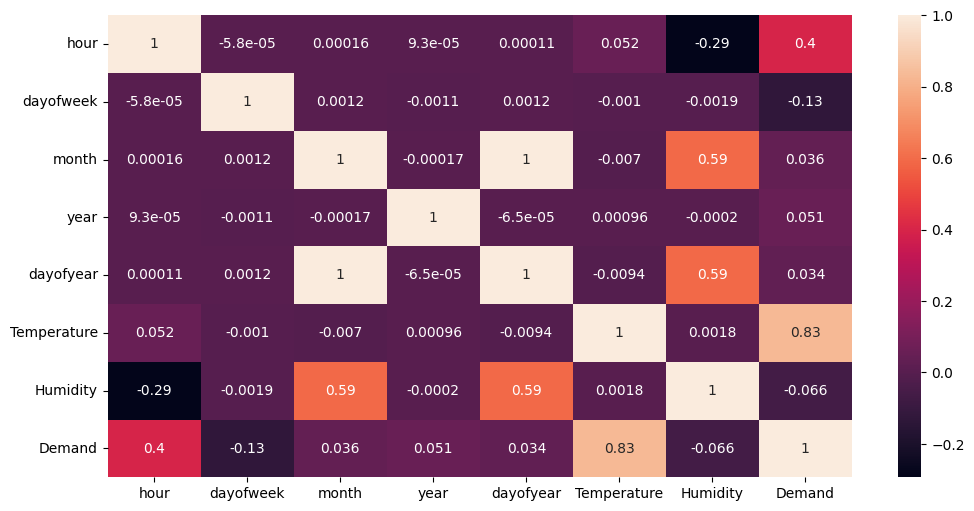

In [ ]:
plt.figure(figsize=(12,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

# Applied Gradient_Boosting

In [ ]:
gb= GradientBoostingRegressor()
gb.fit(x_train, y_train)

GradientBoostingRegressor()

In [ ]:
y_pred= gb.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

rmse = np.sqrt(mse)
print(rmse)
print(f"R-squared: {r2:.4f}")

177.0378063643877
31342.384882314433
R-squared: 0.9846


#Applied XGBoost

In [ ]:
#XGBoost
from xgboost import XGBRegressor
xgb= XGBRegressor()

xgb.fit(x_train,y_train)
y_pred_xgb_train=xgb.predict(x_train)
y_pred_xgb_test=xgb.predict(x_test)

print("Score Train",r2_score(y_train,y_pred_xgb_train))
print("Score Test",r2_score(y_test,y_pred_xgb_test))

Score Train 0.9946434508671138
Score Test 0.9915770124314318


In [1]:
y_pred= xgb.predict(x_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(rmse = np.sqrt(mse))
print(f"R-squared: {r2:.4f}")

NameError: name 'xgb' is not defined